<a href="https://colab.research.google.com/github/192565074simats-code/MLA0201/blob/main/Experiment_14.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

HOUSE PRICE DATASET
    Area  Bedrooms  Bathrooms  Age    Price
0    800         2          1   15  2500000
1   1000         2          2   10  3200000
2   1200         3          2    8  4000000
3   1500         3          2    5  5200000
4   1800         3          3    4  6500000
5   2000         4          3    3  7500000
6    900         2          1   18  2700000
7   1100         2          2   12  3500000
8   1300         3          2    9  4200000
9   1600         3          2    6  5500000
10  1900         4          3    4  6800000
11  2200         4          3    2  8500000
12   950         2          1   20  2400000
13  1250         3          2    7  4100000
14  1700         3          2    5  6000000
15  2100         4          3    3  8000000
16  1400         3          2    8  4500000
17  1550         3          2    6  5300000
18  1850         4          3    4  7000000
19  2300         5          4    1  9500000

Training Samples: 16
Testing Samples: 4

Random Forest 

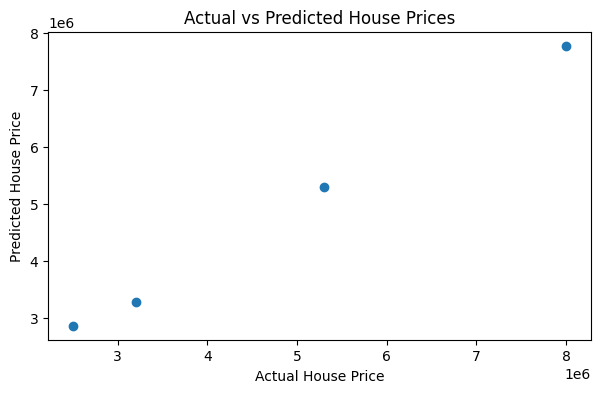

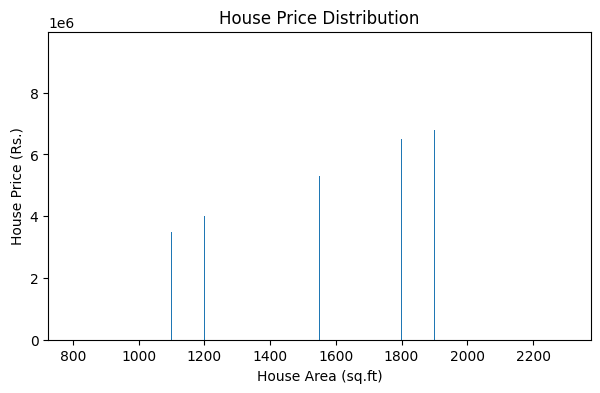

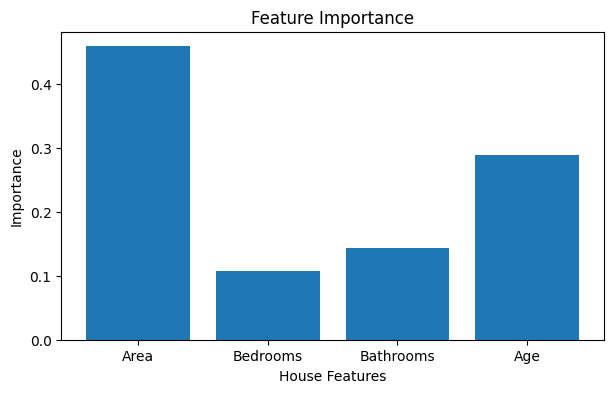


NEW HOUSE DETAILS
   Area  Bedrooms  Bathrooms  Age
0  1600         3          2    5

Predicted House Price: Rs. 5475000.0


In [1]:
# EXPERIMENT 14: HOUSE PRICE PREDICTION

# Step 1: Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Step 2: Create house dataset
data = {
    'Area': [800, 1000, 1200, 1500, 1800, 2000, 900, 1100,
             1300, 1600, 1900, 2200, 950, 1250, 1700,
             2100, 1400, 1550, 1850, 2300],
    'Bedrooms': [2, 2, 3, 3, 3, 4, 2, 2, 3, 3,
                 4, 4, 2, 3, 3, 4, 3, 3, 4, 5],
    'Bathrooms': [1, 2, 2, 2, 3, 3, 1, 2, 2, 2,
                  3, 3, 1, 2, 2, 3, 2, 2, 3, 4],
    'Age': [15, 10, 8, 5, 4, 3, 18, 12, 9, 6,
            4, 2, 20, 7, 5, 3, 8, 6, 4, 1],
    'Price': [2500000, 3200000, 4000000, 5200000,
              6500000, 7500000, 2700000, 3500000,
              4200000, 5500000, 6800000, 8500000,
              2400000, 4100000, 6000000, 8000000,
              4500000, 5300000, 7000000, 9500000]
}

df = pd.DataFrame(data)

print("HOUSE PRICE DATASET")
print(df)

# Step 3: Separate input and output
X = df[['Area', 'Bedrooms', 'Bathrooms', 'Age']]
y = df['Price']

# Step 4: Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("\nTraining Samples:", len(X_train))
print("Testing Samples:", len(X_test))

# Step 5: Train Random Forest model
model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

print("\nRandom Forest Model Trained Successfully!")

# Step 6: Predict house prices
y_pred = model.predict(X_test)

results = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred.round(2)
})

print("\nHOUSE PRICE PREDICTION")
print(results)

# Step 7: Evaluate model
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("\nMean Absolute Error:", round(mae, 2))
print("Mean Squared Error:", round(mse, 2))
print("R2 Score:", round(r2, 2))

# Step 8: Actual vs Predicted Graph
plt.figure(figsize=(7, 4))

plt.scatter(y_test, y_pred)
plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")
plt.title("Actual vs Predicted House Prices")

plt.show()

# Step 9: House Price Distribution
plt.figure(figsize=(7, 4))

plt.bar(df['Area'], df['Price'])

plt.xlabel("House Area (sq.ft)")
plt.ylabel("House Price (Rs.)")
plt.title("House Price Distribution")

plt.show()

# Step 10: Feature Importance Graph
importance = model.feature_importances_

plt.figure(figsize=(7, 4))

plt.bar(X.columns, importance)

plt.xlabel("House Features")
plt.ylabel("Importance")
plt.title("Feature Importance")

plt.show()

# Step 11: Predict New House Price
new_house = pd.DataFrame({
    'Area': [1600],
    'Bedrooms': [3],
    'Bathrooms': [2],
    'Age': [5]
})

predicted_price = model.predict(new_house)

print("\nNEW HOUSE DETAILS")
print(new_house)

print("\nPredicted House Price: Rs.",
      round(predicted_price[0], 2))